# Day 37 — What Right Means
## Evaluation metrics for classification

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

Yesterday you learned to measure **honestly**. Today: measure **what**.

There is still no new model. Everything here works on the logistic regression you
already know, and on the trees and forests coming next week.

| Part | What we do |
|---|---|
| **1** | Four numbers, not one — the confusion matrix |
| **2** | Precision and recall, and why you cannot have both |
| **3** | Squeezing it back down to one number |
| **4** | The whole curve — ROC, AUC, and where they mislead |
| **5** | Putting a price on a mistake |

> **Where this started.** Day 36's practice ended with an HR model that was 90.6%
> accurate, matched its own do-nothing baseline exactly, and caught 2 of the 187 people
> who left. The measurement was wrong in three ways — but the deeper problem was that
> **accuracy was the wrong question**. Today fixes that.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, fbeta_score,
                             balanced_accuracy_score, matthews_corrcoef,
                             roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score,
                             classification_report)

import warnings
warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (8, 3.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("ready")

ready


---
# Part 1 — Four numbers, not one

## The data: 6,000 card payments

| column | what it is |
|---|---|
| `amount` | how much the payment was for |
| `hour` | 0 to 23 |
| `night` | 1 if between 1am and 5am |
| `recent_txns` | payments on this card in the last hour |
| `foreign` | 1 if the merchant is overseas |
| `channel` | chip / online / contactless |
| `fraud` | **1 if the payment was fraudulent** |

In [2]:
r = np.random.default_rng(3700)
N = 6000

amount      = np.round(np.exp(r.normal(3.6, 1.15, N)), 2).clip(1, 5000)
hour        = r.integers(0, 24, N)
recent_txns = r.poisson(1.4, N).clip(0, 12).astype(float)
foreign     = r.binomial(1, 0.09, N).astype(float)
channel     = r.choice(["chip", "online", "contactless"], N, p=[.42, .38, .20])

night = ((hour >= 1) & (hour <= 5)).astype(float)
cb = np.where(channel == "online", 0.80,
     np.where(channel == "contactless", 0.15, -0.45))
z = (-11.0 + 1.5*(0.75*np.log(amount) + 1.6*night + 0.45*recent_txns
                  + 2.0*foreign + 1.4*cb) + r.normal(0, 0.4, N))
fraud = (r.uniform(0, 1, N) < sigmoid(z)).astype(int)

tx = pd.DataFrame({"amount": amount, "hour": hour, "recent_txns": recent_txns,
                   "foreign": foreign, "night": night, "channel": channel,
                   "fraud": fraud})

print(f"payments     : {len(tx):,}")
print(f"fraudulent   : {int(tx.fraud.sum())}   ({tx.fraud.mean():.4f})")
print(f"baseline     : {1 - tx.fraud.mean():.4f}   <- 'never block anything'")
tx.head()

payments     : 6,000
fraudulent   : 290   (0.0483)
baseline     : 0.9517   <- 'never block anything'


,amount,hour,recent_txns,foreign,night,channel,fraud
0,5.71,14,1.0,0.0,0.0,chip,0
1,90.22,6,1.0,0.0,0.0,online,0
2,120.97,4,2.0,0.0,1.0,chip,0
3,20.79,4,2.0,0.0,1.0,chip,1
4,21.67,18,5.0,0.0,0.0,chip,0


In [3]:
print("fraud rate by channel:")
print(tx.groupby("channel").fraud.mean().round(4).to_string())
print()
print(f"foreign merchants are {tx.foreign.mean():.1%} of payments")
print(f"   fraud rate when foreign : {tx[tx.foreign == 1].fraud.mean():.4f}")
print(f"   fraud rate otherwise    : {tx[tx.foreign == 0].fraud.mean():.4f}")
print()
print(f"median fraudulent payment : {tx[tx.fraud == 1].amount.median():.2f}")
print(f"median honest payment     : {tx[tx.fraud == 0].amount.median():.2f}")

fraud rate by channel:
channel
chip           0.0103
contactless    0.0322
online         0.0983

foreign merchants are 9.2% of payments
   fraud rate when foreign : 0.2101
   fraud rate otherwise    : 0.0319

median fraudulent payment : 90.61
median honest payment     : 35.34


### Fit it, the Day 36 way

Cross-validated predictions for **every row** — so every payment is scored by a model
that never saw it. Nothing in this notebook uses a score from rows the model studied.

In [4]:
NUM = ["amount", "recent_txns", "foreign", "night"]
CAT = ["channel"]

pipe = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), NUM),
                                ("cat", OneHotEncoder(drop="first"), CAT)])),
    ("model", LogisticRegression(max_iter=2000))])

X, y = tx[NUM + CAT], tx.fraud
cv = StratifiedKFold(5, shuffle=True, random_state=0)

probs = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
pred  = (probs >= 0.5).astype(int)

print("probabilities for the first 8 payments:", np.round(probs[:8], 4))
print("the 0.5 decision for those:            ", pred[:8])

probabilities for the first 8 payments: [0.0012 0.018  0.0258 0.0163 0.0111 0.0312 0.4204 0.1422]
the 0.5 decision for those:             [0 0 0 0 0 0 0 0]


## The confusion matrix

Every prediction lands in **exactly one of four boxes**:

| | predicted legit | predicted fraud |
|---|---|---|
| **actually legit** | true negative — said legit, was legit | false positive — said fraud, was legit |
| **actually fraud** | **false negative** — said legit, was fraud | true positive — said fraud, was fraud |

Learn these four names properly today. Every metric for the rest of the course is built
out of them.

In [5]:
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()      # note the order!

print(f"                 predicted legit   predicted fraud")
print(f"actually legit   {tn:>13,}   {fp:>15,}")
print(f"actually fraud   {fn:>13,}   {tp:>15,}")
print()
print(f"accuracy    = (tp + tn) / everything  = {(tp+tn)/len(y):.4f}")
print(f"precision   =  tp / (tp + fp)         = {tp/(tp+fp):.4f}   = {tp}/{tp+fp}")
print(f"recall      =  tp / (tp + fn)         = {tp/(tp+fn):.4f}   = {tp}/{tp+fn}")
print(f"specificity =  tn / (tn + fp)         = {tn/(tn+fp):.4f}")

                 predicted legit   predicted fraud
actually legit           5,683                27
actually fraud             223                67

accuracy    = (tp + tn) / everything  = 0.9583
precision   =  tp / (tp + fp)         = 0.7128   = 67/94
recall      =  tp / (tp + fn)         = 0.2310   = 67/290
specificity =  tn / (tn + fp)         = 0.9953


### Stop and read the bottom-left box

**223 frauds went straight through.** The model saw them and said "legit".

That number does not appear in the accuracy figure, it does not appear in the precision
figure, and it is the single most important thing on the page.

## The accuracy trap, one more time

0.9583 sounds excellent. Let us put it next to the only number that gives it meaning.

In [6]:
baseline = 1 - y.mean()
acc = accuracy_score(y, pred)

print(f"the model (0.5 cut-off)     : {acc:.4f}")
print(f"'every payment is legit'    : {baseline:.4f}")
print(f"the gain                    : {acc - baseline:+.4f}")
print()
print("the 'always legit' model needs no data, no columns and no training.")

the model (0.5 cut-off)     : 0.9583
'every payment is legit'    : 0.9517
the gain                    : +0.0067

the 'always legit' model needs no data, no columns and no training.


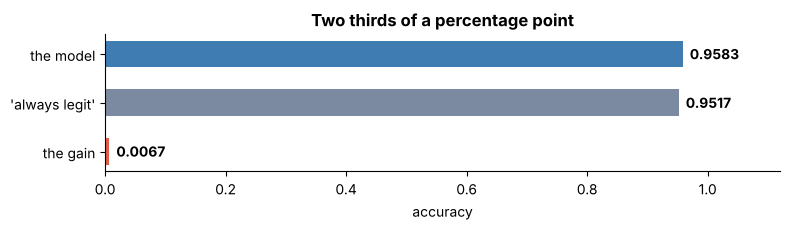

In [7]:
plt.figure(figsize=(8, 2.4))
plt.barh([2, 1, 0], [acc, baseline, acc - baseline], 0.55,
         color=["#3E7CB1", "#7B8AA1", "#E05C45"])
for i, v in zip([2, 1, 0], [acc, baseline, acc - baseline]):
    plt.text(v + 0.012, i, f"{v:.4f}", va="center", fontweight="bold")
plt.yticks([2, 1, 0], ["the model", "'always legit'", "the gain"])
plt.xlim(0, 1.12); plt.xlabel("accuracy")
plt.title("Two thirds of a percentage point", fontweight="bold")
plt.tight_layout(); plt.show()

**Two thirds of a percentage point** is the entire contribution of this model, measured
the way most people measure.

And yet — hold that thought. By the end of Part 4 you will see that this same model
ranks fraud above honest payments **91% of the time**. It is a genuinely good model being
described by a genuinely useless number.

---
# Part 2 — Precision and recall

Two fractions. **Same numerator. Different denominators.**

```
precision =  67 / 94   = 0.7128      of everything we FLAGGED, how much was fraud?
recall    =  67 / 290  = 0.2310      of all the fraud THAT HAPPENED, how much did we get?
```

- **Precision** is about the model's claims. Denominator: the 94 cards we blocked.
- **Recall** is about the world's cases. Denominator: the 290 frauds that occurred.

A way to keep them straight: *precision asks about the 94; recall asks about the 290.*

In [8]:
print(f"precision_score : {precision_score(y, pred):.4f}")
print(f"recall_score    : {recall_score(y, pred):.4f}")
print()
print(f"by hand         : {tp}/{tp+fp} = {tp/(tp+fp):.4f}   and   {tp}/{tp+fn} = {tp/(tp+fn):.4f}")

precision_score : 0.7128
recall_score    : 0.2310

by hand         : 67/94 = 0.7128   and   67/290 = 0.2310


## The trade-off

`.predict()` silently compares the probability to **0.5**. Nothing says it has to.

Move that number and watch precision and recall move in opposite directions.

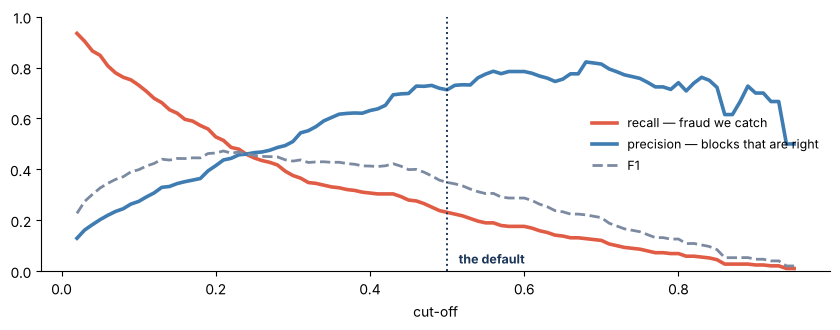

best F1 is 0.4723 at a cut-off of 0.21


In [9]:
grid = np.round(np.arange(0.02, 0.96, 0.01), 2)
prec_list, rec_list, f1_list = [], [], []
for t in grid:
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    pr = d/(d+b) if d+b else np.nan
    rc = d/(d+c)
    prec_list.append(pr); rec_list.append(rc)
    f1_list.append(2*pr*rc/(pr+rc) if pr and rc else 0)

plt.figure(figsize=(8.5, 3.4))
plt.plot(grid, rec_list, color="#E05C45", lw=2.6, label="recall — fraud we catch")
plt.plot(grid, prec_list, color="#3E7CB1", lw=2.6, label="precision — blocks that are right")
plt.plot(grid, f1_list, color="#7B8AA1", lw=2, ls="--", label="F1")
plt.axvline(0.5, color="#1B3558", lw=1.4, ls=":")
plt.text(0.515, 0.03, "the default", color="#1B3558", fontweight="bold", fontsize=9)
plt.xlabel("cut-off"); plt.ylim(0, 1); plt.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

best = int(np.nanargmax(f1_list))
print(f"best F1 is {f1_list[best]:.4f} at a cut-off of {grid[best]:.2f}")

In [10]:
print(f"{'cut-off':>8}{'blocked':>9}{'caught':>8}{'missed':>8}"
      f"{'precision':>11}{'recall':>9}{'accuracy':>10}")
print("-" * 63)
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 0.70, 0.90]:
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    print(f"{t:>8}{d+b:>9,}{d:>8}{c:>8}{d/(d+b):>11.4f}{d/(d+c):>9.4f}"
          f"{(pp == y).mean():>10.4f}")

 cut-off  blocked  caught  missed  precision   recall  accuracy
---------------------------------------------------------------
    0.05    1,216     246      44     0.2023   0.8483    0.8310
     0.1      774     212      78     0.2739   0.7310    0.8933
    0.15      523     180     110     0.3442   0.6207    0.9245
     0.2      369     153     137     0.4146   0.5276    0.9412
     0.3      214     109     181     0.5093   0.3759    0.9523
     0.5       94      67     223     0.7128   0.2310    0.9583
     0.7       43      35     255     0.8140   0.1207    0.9562
     0.9       10       7     283     0.7000   0.0241    0.9523


### Three things in that table

**Accuracy is highest at 0.50** — the row that misses 223 of the 290 frauds. On
imbalanced data, maximising accuracy is a way of asking the model to do nothing.

**At 0.90, precision actually falls** to 0.7000, after rising all the way up from 0.2023.
That is not a bug: only 10 cards get flagged at that cut-off, so one mistake moves
precision by ten points. **Precision is noisy when the flagged set is tiny**, and you
should distrust any precision computed from a handful of cases.

**Nothing about the model changed down that table.** Not a coefficient, not a row of
data. Only the number the probability is compared against.

## So which one do you want?

| recall matters more | precision matters more |
|---|---|
| a cancer screen | blocking someone's card |
| fraud on a large account | auto-rejecting a job application |
| a safety alert on a machine | flagging a customer to the police |
| *missing a case is catastrophic; a false alarm costs a review* | *acting wrongly does real harm to a real person* |

**Card fraud is genuinely both**, which is why it is a good example. Miss a fraud and the
bank refunds it. Block a real customer and they are stranded at a till in another
country.

Part 5 settles it with money, because nothing else can.

> You cannot answer "which metric" by looking at the model. You answer it by asking
> **who gets hurt by each kind of mistake**.

---
# Part 3 — Back down to one number

Sometimes you really do have to report a single figure — to compare twenty models, or to
put one number in a slide. The usual choice is **F1**:

```
            2 · precision · recall
     F1  =  ———————————————————————
              precision + recall
```

That is the **harmonic** mean, not the plain average, and the difference is the whole
point.

In [11]:
print(f"{'precision':>10}{'recall':>9}{'plain average':>15}{'F1':>9}")
print("-" * 43)
for p_, r_ in [(0.90, 0.90), (0.90, 0.50), (0.90, 0.10), (0.95, 0.02), (0.50, 0.50)]:
    print(f"{p_:>10.2f}{r_:>9.2f}{(p_+r_)/2:>15.3f}{2*p_*r_/(p_+r_):>9.3f}")
print()
print(f"our model at 0.5:  f1_score = {f1_score(y, pred):.4f}")

 precision   recall  plain average       F1
-------------------------------------------
      0.90     0.90          0.900    0.900
      0.90     0.50          0.700    0.643
      0.90     0.10          0.500    0.180
      0.95     0.02          0.485    0.039
      0.50     0.50          0.500    0.500

our model at 0.5:  f1_score = 0.3490


### Look at the fourth row

Precision 0.95 with recall 0.02 is a system that blocks about four cards a year and is
usually right about them. It is useless.

**A plain average calls that 0.485** — half marks, a passable model. **F1 calls it
0.039.**

The harmonic mean is dragged towards the *smaller* of the two numbers. It refuses to let
one good score hide a terrible one, and that is exactly what you want from a summary.

## The one knob: F-beta

`beta` is **how many times more you care about recall than precision**.

In [12]:
for beta, note in [(0.5, "precision counts double"),
                   (1.0, "they count equally  (this is F1)"),
                   (2.0, "recall counts double")]:
    print(f"F{beta:<4} = {fbeta_score(y, pred, beta=beta):.4f}    {note}")

F0.5  = 0.5030    precision counts double
F1.0  = 0.3490    they count equally  (this is F1)
F2.0  = 0.2671    recall counts double


Choosing `beta` is the same decision as choosing a cut-off, moved one step earlier — and
it is just as impossible to make without knowing what the mistakes cost.

## Two more single numbers worth knowing

In [13]:
print(f"balanced accuracy : {balanced_accuracy_score(y, pred):.4f}")
print(f"   = the average of recall on each class")
print(f"   = ({recall_score(y, pred):.4f} + {tn/(tn+fp):.4f}) / 2 "
      f"= {(recall_score(y, pred) + tn/(tn+fp))/2:.4f}")
print()
print(f"Matthews corr.    : {matthews_corrcoef(y, pred):.4f}")
print(f"   uses all four boxes; runs -1 to +1, where 0 is chance")
print()
always_legit = np.zeros(len(y), dtype=int)
print("and what the do-nothing model scores on each:")
print(f"   accuracy          : {accuracy_score(y, always_legit):.4f}   <- looks great")
print(f"   balanced accuracy : {balanced_accuracy_score(y, always_legit):.4f}   <- exactly 0.5")
print(f"   F1                : {f1_score(y, always_legit):.4f}")
print(f"   Matthews          : {matthews_corrcoef(y, always_legit):.4f}")

balanced accuracy : 0.6132
   = the average of recall on each class
   = (0.2310 + 0.9953) / 2 = 0.6132

Matthews corr.    : 0.3908
   uses all four boxes; runs -1 to +1, where 0 is chance

and what the do-nothing model scores on each:
   accuracy          : 0.9517   <- looks great
   balanced accuracy : 0.5000   <- exactly 0.5
   F1                : 0.0000
   Matthews          : 0.0000


### That last block is the argument for all three

The do-nothing model scores **0.9517 on accuracy** and **0.5000, 0.0000 and 0.0000** on
the other three. Balanced accuracy, F1 and MCC all refuse to be impressed by it; accuracy
cannot tell it apart from a real model.

### But an honest warning about every number in this Part

Each one squeezes a **two-dimensional** trade-off into **one** dimension, and to do that
it has to assume something about what you care about:

- **F1** assumes precision and recall matter equally
- **balanced accuracy** assumes the two classes matter equally
- **MCC** assumes something subtler, and is hard to explain in a meeting

None of those assumptions is likely to be true for your problem. Use these to compare
models on a level field. **Do not use them to choose a cut-off** — Part 5 has a better
way.

## Three defensible rules, three different banks

Suppose you have no cost information and must pick a cut-off anyway. Here are three
rules that all sound reasonable in a meeting.

In [14]:
grid = np.round(np.arange(0.01, 0.96, 0.01), 2)
rules = {
    "maximise F1":                max(grid, key=lambda t: f1_score(y, (probs >= t).astype(int))),
    "maximise balanced accuracy": max(grid, key=lambda t: balanced_accuracy_score(y, (probs >= t).astype(int))),
    "maximise plain accuracy":    max(grid, key=lambda t: ((probs >= t).astype(int) == y).mean()),
}
print(f"{'rule':<28}{'cut-off':>9}{'blocked':>9}{'recall':>9}{'precision':>11}{'accuracy':>10}")
print("-" * 76)
for name, t in rules.items():
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    print(f"{name:<28}{t:>9.2f}{d+b:>9,}{d/(d+c):>9.4f}{d/(d+b):>11.4f}{(pp == y).mean():>10.4f}")

rule                          cut-off  blocked   recall  precision  accuracy
----------------------------------------------------------------------------
maximise F1                      0.21      341   0.5138     0.4370    0.9445
maximise balanced accuracy       0.05    1,216   0.8483     0.2023    0.8310
maximise plain accuracy          0.46      110   0.2759     0.7273    0.9600


**One blocks 341 cards. One blocks 1,216. One blocks 110.**

Every one of those is a different bank, a different customer experience and a different
number of frauds getting through — and all three rules would survive a meeting.

The disagreement is not a technical detail to be resolved by picking the best metric. It
*is* the business decision, and no metric can make it for you.

---
# Part 4 — The whole curve, not one point

Every number so far depended on a cut-off. Two measures do not: they score the model at
**every cut-off at once**, which makes them the right tool for *comparing models*.

In [15]:
# a deliberately weaker model, for comparison, and pure chance
weak = Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000))])
probs_weak = cross_val_predict(weak, tx[["amount"]], y, cv=cv,
                               method="predict_proba")[:, 1]
probs_coin = np.random.default_rng(3).uniform(0, 1, len(y))

for nm, pp in [("all five columns", probs), ("amount only", probs_weak),
               ("random guessing", probs_coin)]:
    print(f"{nm:<20} ROC AUC {roc_auc_score(y, pp):.4f}    "
          f"average precision {average_precision_score(y, pp):.4f}")
print()
print(f"{'the fraud rate itself':<20} {'':>8}         "
      f"average precision {y.mean():.4f}   <- the no-skill level")

all five columns     ROC AUC 0.9141    average precision 0.4528
amount only          ROC AUC 0.7267    average precision 0.1239
random guessing      ROC AUC 0.4970    average precision 0.0477

the fraud rate itself                  average precision 0.0483   <- the no-skill level


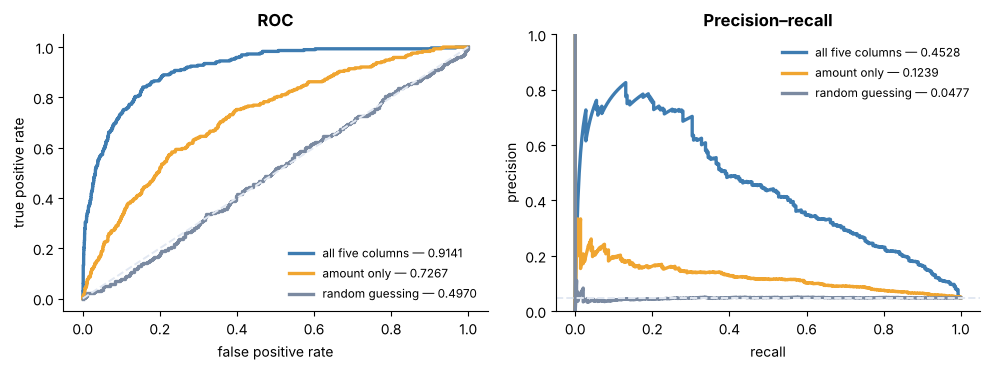

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for pp, nm, c in [(probs, "all five columns", "#3E7CB1"),
                  (probs_weak, "amount only", "#F0A530"),
                  (probs_coin, "random guessing", "#7B8AA1")]:
    f_, t_, _ = roc_curve(y, pp)
    axes[0].plot(f_, t_, color=c, lw=2.4, label=f"{nm} — {roc_auc_score(y, pp):.4f}")
    pr_, rc_, _ = precision_recall_curve(y, pp)
    axes[1].plot(rc_, pr_, color=c, lw=2.4,
                 label=f"{nm} — {average_precision_score(y, pp):.4f}")
axes[0].plot([0, 1], [0, 1], color="#E2E8F2", lw=1.4, ls="--")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC", fontweight="bold"); axes[0].legend(frameon=False, fontsize=8.5)
axes[1].axhline(y.mean(), color="#E2E8F2", lw=1.4, ls="--")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_ylim(0, 1)
axes[1].set_title("Precision–recall", fontweight="bold")
axes[1].legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

## What AUC actually means — and how to check it

> **Pick one fraud and one honest payment at random. AUC is the chance the model gave the
> fraud the higher score.**

That is not an analogy. It is the definition, and we can verify it by brute force.

In [17]:
rng = np.random.default_rng(7)
pf, pl = probs[y == 1], probs[y == 0]

T = 400_000
i = rng.integers(0, len(pf), T)
j = rng.integers(0, len(pl), T)
wins = (pf[i] > pl[j]).sum()

print(f"sampled {T:,} random (fraud, legit) pairs")
print(f"   the fraud scored higher in : {wins/T:.4f} of them")
print(f"   roc_auc_score says         : {roc_auc_score(y, probs):.4f}")

sampled 400,000 random (fraud, legit) pairs
   the fraud scored higher in : 0.9142 of them
   roc_auc_score says         : 0.9141


Two numbers computed in completely different ways, agreeing to three decimal places.

**So AUC measures the RANKING, not the decisions.** It never looks at your cut-off —
which is why a model can have an excellent AUC and still be useless as deployed. Ours has
AUC 0.9141 and catches 23% of fraud at the default.

- **0.5** — the ranking is a coin flip
- **1.0** — every fraud outranks every honest payment
- **0.9141** — it gets the pair right about nine times in ten

## Where ROC quietly flatters you

Here is the experiment that matters. **The model never changes.** We just score it on
test sets where fraud is progressively rarer.

In [18]:
rng = np.random.default_rng(11)
fr = np.where(y == 1)[0]
lg = np.where(y == 0)[0]

print(f"{'fraud rate':>12}{'n fraud':>9}{'ROC AUC':>10}{'avg precision':>15}")
print("-" * 46)
for keep in [290, 145, 58, 29]:
    sel = np.concatenate([rng.choice(fr, keep, replace=False), lg])
    ys, ps = y.values[sel], probs[sel]
    print(f"{ys.mean():>12.4f}{keep:>9}{roc_auc_score(ys, ps):>10.4f}"
          f"{average_precision_score(ys, ps):>15.4f}")

  fraud rate  n fraud   ROC AUC  avg precision
----------------------------------------------
      0.0483      290    0.9141         0.4528
      0.0248      145    0.9098         0.3190
      0.0101       58    0.9322         0.1730
      0.0051       29    0.8949         0.0740


### ROC AUC held near 0.91. Average precision fell from 0.4528 to 0.0740.

The same model, every single row. Only the share of fraud in the test set changed.

**Why?** ROC's false positive rate divides by the number of honest payments — and on
imbalanced data that number is enormous, so the denominator swamps any number of false
alarms.

In [19]:
print(f"{'cut-off':>9}{'false alarms':>14}{'false positive rate':>21}{'precision':>12}")
print("-" * 58)
for t in [0.05, 0.10, 0.20]:
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    print(f"{t:>9}{b:>14,}{b/(b+a):>21.4f}{d/(d+b):>12.4f}")

  cut-off  false alarms  false positive rate   precision
----------------------------------------------------------
     0.05           970               0.1699      0.2023
      0.1           562               0.0984      0.2739
      0.2           216               0.0378      0.4146


**970 wrongly blocked cards is 17% of honest payments** — which sounds forgivable.

It is also **four out of every five blocks the bank makes**, and that is what the
customer experiences.

### So which curve

| use | when |
|---|---|
| **ROC / AUC** | comparing models on the same data · classes roughly balanced · you want one cut-off-free number |
| **precision-recall / AP** | one class is rare (under ~10%) · you care about the positives specifically |
| **neither** | you already know what each mistake costs — then Part 5 beats both |

> A habit worth keeping: whenever somebody shows you an **AUC above 0.9 on a rare event**,
> ask for the precision-recall curve too. It is one line, and it often changes the
> conversation.

---
# Part 5 — Putting a price on it

Everything so far has been a proxy. Here is the real thing.

- a fraud we **miss** costs the bank the value of the payment
- a good card we **block** costs the bank some fixed amount — support time, goodwill, the
  chance the customer moves bank

That second number is uncomfortable to estimate. But **choosing a metric instead does not
avoid the estimate — it just hides it, and makes it badly.**

In [20]:
amt = tx.amount.values

def total_cost(threshold, cost_of_a_block):
    pp = (probs >= threshold).astype(int)
    missed  = amt[(y == 1) & (pp == 0)].sum()
    blocked = int(((pp == 1) & (y == 0)).sum())
    return missed + cost_of_a_block * blocked

print(f"total value of all fraud in the data : {amt[y == 1].sum():>12,.0f}")
print(f"block nothing                        : {total_cost(1.01, 50):>12,.0f}")
print(f"block everything (at 50 each)        : {total_cost(0.00, 50):>12,.0f}")

total value of all fraud in the data :       44,478
block nothing                        :       44,478
block everything (at 50 each)        :      285,500


In [21]:
print("cost of a wrongly blocked card = 50")
print(f"{'cut-off':>9}{'blocked':>9}{'caught':>8}{'fraud lost':>13}{'block cost':>13}{'total':>12}")
print("-" * 65)
for t in [0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 0.70]:
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    lost = amt[(y == 1) & (pp == 0)].sum()
    print(f"{t:>9}{d+b:>9,}{d:>8}{lost:>13,.0f}{50*b:>13,.0f}{lost + 50*b:>12,.0f}")

cost of a wrongly blocked card = 50
  cut-off  blocked  caught   fraud lost   block cost       total
-----------------------------------------------------------------
     0.02    2,098     271        1,803       91,350      93,153
     0.05    1,216     246        4,105       48,500      52,605
      0.1      774     212        9,257       28,100      37,357
     0.15      523     180       13,157       17,150      30,307
      0.2      369     153       16,859       10,800      27,659
      0.3      214     109       23,961        5,250      29,211
      0.5       94      67       30,296        1,350      31,646
      0.7       43      35       35,371          400      35,771


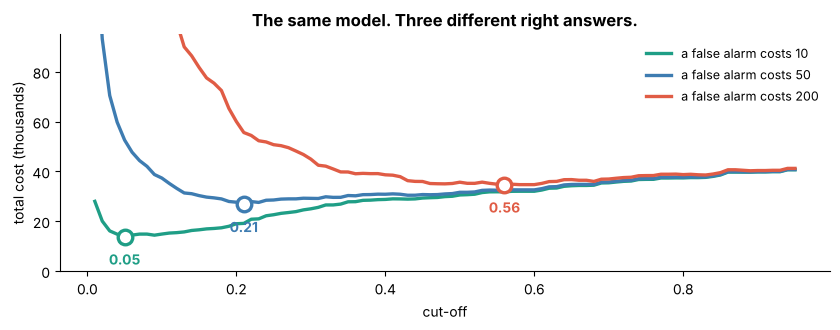

In [22]:
grid = np.round(np.arange(0.01, 0.96, 0.01), 2)
plt.figure(figsize=(8.5, 3.4))
for bc, c in [(10, "#1F9E86"), (50, "#3E7CB1"), (200, "#E05C45")]:
    tot = np.array([total_cost(t, bc) for t in grid])
    plt.plot(grid, tot/1000, color=c, lw=2.4, label=f"a false alarm costs {bc}")
    k = int(tot.argmin())
    plt.scatter([grid[k]], [tot[k]/1000], s=110, facecolor="white", edgecolor=c, lw=2.4,
                zorder=5)
    plt.annotate(f"{grid[k]:.2f}", (grid[k], tot[k]/1000), textcoords="offset points",
                 xytext=(0, -20), ha="center", color=c, fontweight="bold")
plt.xlabel("cut-off"); plt.ylabel("total cost (thousands)"); plt.ylim(0, 95)
plt.legend(frameon=False, fontsize=9)
plt.title("The same model. Three different right answers.", fontweight="bold")
plt.tight_layout(); plt.show()

In [23]:
print(f"{'block cost':>12}{'cheapest cut-off':>19}{'blocked':>9}{'caught':>8}{'recall':>9}")
print("-" * 58)
for bc in [5, 10, 25, 50, 100, 200, 400]:
    costs = np.array([total_cost(t, bc) for t in grid])
    t = grid[int(costs.argmin())]
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    print(f"{bc:>12}{t:>19.2f}{d+b:>9,}{d:>8}{d/(d+c):>9.4f}")

  block cost   cheapest cut-off  blocked  caught   recall
----------------------------------------------------------
           5               0.05    1,216     246   0.8483
          10               0.05    1,216     246   0.8483
          25               0.13      583     192   0.6621
          50               0.21      341     149   0.5138
         100               0.46      110      80   0.2759
         200               0.56       70      55   0.1897
         400               0.58       65      51   0.1759


### The cut-off moved from 0.05 to 0.58

**The model never changed.** Not one coefficient. Only the price of a mistake did.

At ₹5 a block, take 0.05 and catch **85%** of fraud. At ₹400, take 0.58 and catch **18%**.
**Both are correct.** The question was never "which cut-off is best" — it was "best for
whom, at what price".

> Notice what this calculation did **not** need: a metric. It needed the confusion matrix
> and a price list.

## More than two classes

The confusion matrix just gets bigger. Precision and recall still work — they are
computed one class at a time, each class taking its turn as "the positive one".

1,800 support tickets, triaged into **low / medium / high** priority.

In [24]:
r = np.random.default_rng(3710)
M = 1800

wait_hours = r.exponential(9, M).clip(0, 90).round(0)
words      = r.normal(60, 28, M).clip(5, 300).round(0)
paying     = r.binomial(1, 0.42, M).astype(float)
angry      = r.binomial(1, 0.23, M).astype(float)

s_ = -1.2 + 0.035*wait_hours + 0.009*words + 1.1*paying + 1.4*angry + r.normal(0, 0.7, M)
priority = np.where(s_ > 2.2, "high", np.where(s_ > 0.9, "medium", "low"))

tickets = pd.DataFrame({"wait_hours": wait_hours, "words": words,
                        "paying": paying, "angry": angry, "priority": priority})
print(tickets.priority.value_counts().to_string())

Xt, yt = tickets[["wait_hours", "words", "paying", "angry"]], tickets.priority
pt = cross_val_predict(Pipeline([("sc", StandardScaler()),
                                 ("m", LogisticRegression(max_iter=2000))]),
                       Xt, yt, cv=StratifiedKFold(5, shuffle=True, random_state=0))

priority
low       1180
medium     495
high       125


In [25]:
labs = ["low", "medium", "high"]
cm = confusion_matrix(yt, pt, labels=labs)
print("rows = what it really was, columns = what the model said\n")
print(pd.DataFrame(cm, index=labs, columns=labs).to_string())
print(f"\naccuracy: {accuracy_score(yt, pt):.4f}")

rows = what it really was, columns = what the model said

         low  medium  high
low     1063     117     0
medium   221     251    23
high       9      65    51

accuracy: 0.7583


In [26]:
print(classification_report(yt, pt, labels=labs, digits=4))

              precision    recall  f1-score   support

         low     0.8221    0.9008    0.8597      1180
      medium     0.5797    0.5071    0.5409       495
        high     0.6892    0.4080    0.5126       125

    accuracy                         0.7583      1800
   macro avg     0.6970    0.6053    0.6377      1800
weighted avg     0.7462    0.7583    0.7479      1800



### Read that report bottom-up, then top-down

The three rows at the **bottom** are the summary everybody quotes. The three rows at the
**top** are where the problem actually is.

**`high` has recall 0.4080 on a support of 125.** The model misses 74 of the 125 genuinely
urgent tickets — and the accuracy line says 0.7583.

Always check `support` before trusting a rate computed from it.

### macro, weighted, micro

| average | what it does | here |
|---|---|---|
| **macro** | the plain mean of each class's F1 — every class counts the same | 0.6377 |
| **weighted** | weighted by how common each class is — big classes dominate | 0.7479 |
| **micro** | pools all predictions first — equals accuracy for single-label problems | 0.7583 |

In [27]:
for avg in ["macro", "weighted", "micro"]:
    print(f"{avg:>10} F1 : {f1_score(yt, pt, average=avg):.4f}")
print()
print("per class:")
for lab, f in zip(labs, f1_score(yt, pt, labels=labs, average=None)):
    print(f"   {lab:<8} {f:.4f}")

     macro F1 : 0.6377
  weighted F1 : 0.7479
     micro F1 : 0.7583

per class:
   low      0.8597
   medium   0.5409
   high     0.5126


**'high priority' is 7% of tickets.** Weighted averaging lets the easy 'low' class answer
for the whole model — 0.7479 against macro's 0.6377.

> **Report macro when the rare class is the one you care about.** Which, in almost every
> problem worth automating, it is.

---
# The four habits

| | | |
|---|---|---|
| **1** | **Look at four numbers** | the confusion matrix, before any metric |
| **2** | **Name the costly mistake** | a missed fraud, or a blocked customer? |
| **3** | **Choose the cut-off from that cost** | not from 0.5, and not from a metric |
| **4** | **Quote the baseline** | next to every number you report |

The model produced **one ranking** of 6,000 payments. Everything after that — the cut-off,
the metric, the number in the report — was a decision a person made.

## Mistakes this notebook should stop you making

| if you catch yourself... | what is wrong | do this instead |
|---|---|---|
| reporting accuracy on rare events | 'never block' scored 0.9517 here | quote the baseline beside it |
| quoting precision without recall | or recall without precision | quote both, and say which cut-off |
| using `.predict()` for a curve | that is one point, not a curve | pass `.predict_proba()[:, 1]` |
| showing ROC for a rare class | the false positive rate stays flatteringly small | show precision-recall too |
| choosing the cut-off that maximises accuracy | on imbalanced data that is close to doing nothing | choose it from what mistakes cost |
| reporting weighted F1 when the rare class matters | the big easy class answers for the model | report macro F1, or per-class |

**Five of those six make your headline number go up.** That is what makes them survive
review.

## Five numbers from today

- **0.9583** — the accuracy of a model that let 223 of 290 frauds through, against a
  0.9517 baseline
- **0.7128 / 0.2310** — its precision and recall at that same cut-off, pointing in
  opposite directions
- **0.039** — F1 for precision 0.95 with recall 0.02; a plain average would have said
  0.485
- **0.9141** — ROC AUC, which barely moved as fraud fell to 0.51% while average precision
  collapsed to 0.0740
- **0.05 → 0.58** — the cheapest cut-off as the price of a wrongly blocked card went from
  ₹5 to ₹400

---

**Next:** k-Nearest Neighbours — the first model that does not fit an equation at all.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*